<div dir="rtl">

# ۰۳ — آمار توصیفی، نمودارها و مقایسه‌ی گروه‌ها

**تسک‌های فاز اول که اینجا انجام می‌شوند:**

| بخش | تسک |
|---|---|
| ۱. جدول‌های فراوانی | تسک ۶ |
| ۲. مرکز و پراکندگی | تسک ۷ |
| ۳. نمودارها (۶ نمودار) | تسک ۸ |
| ۴. مقایسه‌ی توصیفی سه گروه سیگار | تسک ۹ |
| ۵. خلاصه‌ی ساده در برابر وزن‌دار | تسک الف.۳ |

**قاعده‌ی مهم این فاز:** همه‌چیز **توصیفی** است. هیچ آزمون فرض یا ادعای «معنادار بودن» انجام نمی‌شود؛ آن کار فاز سوم است.

تمام جدول‌ها در `reports/phase1/` و تمام نمودارها در `figures/` ذخیره می‌شوند تا مستقیم در گزارش استفاده شوند.

</div>

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path("..").resolve() / "src"))
import nhanes as nh

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

FIG_DIR = Path("..") / "figures"
TAB_DIR = Path("..") / "reports" / "phase1"
FIG_DIR.mkdir(exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# Rebuild the analytic sample from raw files (same steps as notebook 01)
merged = nh.add_derived_variables(
    nh.merge_files(nh.load_raw("DEMO_L"), nh.load_raw("SLQ_L"), nh.load_raw("SMQ_L"))
)
df, flow = nh.build_analytic_sample(merged)
W = df["WTINT2YR"]
GROUPS = ["never", "former", "current"]
print(f"Analytic sample: {len(df):,} adults")

Analytic sample: 7,996 adults


<div dir="rtl">

### سبک نمودارها

همه‌ی نمودارها یک سبک یکسان دارند: پس‌زمینه‌ی روشن، خطوط شبکه‌ی کم‌رنگ، متن خاکستری تیره، و **هر گروه سیگار در همه‌ی نمودارها همیشه یک رنگ ثابت دارد** (هرگز = آبی، سابق = نارنجی، فعلی = سبز‌آبی). برچسب‌های نمودارها انگلیسی‌اند چون matplotlib متن فارسی را درست نمایش نمی‌دهد.

</div>

In [4]:
COLORS = {"never": "#2a78d6", "former": "#eb6834", "current": "#1baf7a"}
LABELS = {"never": "Never smoker", "former": "Former smoker", "current": "Current smoker"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "savefig.dpi": 300, "savefig.bbox": "tight",
})

def save(fig, name):
    fig.savefig(FIG_DIR / name)
    print(f"Saved figures/{name}")

<div dir="rtl">

## ۱. جدول‌های فراوانی (تسک ۶)

برای متغیرهای طبقه‌ای: تعداد، درصد در نمونه، و **درصد وزن‌دار** (برآورد سهم در جمعیت آمریکا).

</div>

In [5]:
def freq_table(series, name):
    counts = series.value_counts().reindex(series.dropna().unique())
    out = pd.DataFrame({
        "n": counts,
        "pct_sample": counts / counts.sum() * 100,
        "pct_weighted": [nh.weighted_share(series == k, W) * 100 for k in counts.index],
    })
    out.index.name = name
    return out

sex_label = df["sex"]
smoke_label = df["smoking_status"].astype(str)
short_label = df["short_sleep"].map({1.0: "short (<7 h)", 0.0: "not short (>=7 h)"})

freq_smoking = freq_table(smoke_label, "smoking_status").reindex(GROUPS)
freq_sex = freq_table(sex_label, "sex")
freq_short = freq_table(short_label, "short_sleep")

for t, f in [(freq_smoking, "freq_smoking.csv"), (freq_sex, "freq_sex.csv"), (freq_short, "freq_short_sleep.csv")]:
    t.round(2).to_csv(TAB_DIR / f)
    display(t)

,n,pct_sample,pct_weighted
smoking_status,,,
never,4823,60.32,63.01
former,2020,25.26,22.92
current,1153,14.42,14.08


,n,pct_sample,pct_weighted
sex,,,
male,3572,44.67,48.34
female,4424,55.33,51.66


,n,pct_sample,pct_weighted
short_sleep,,,
not short (>=7 h),6401,80.05,80.89
short (<7 h),1595,19.95,19.11


<div dir="rtl">

**الگوهای مهم:**
- حدود ۱۴٪ نمونه سیگاری فعلی‌اند و این سهم با وزن هم تقریباً همین است.
- حدود ۲۰٪ بزرگسالان خواب کوتاه (کمتر از ۷ ساعت در میانگین هفتگی) گزارش کرده‌اند.
- سهم زنان در نمونه کمی بیشتر از مردان است؛ وزن‌دهی این را به نسبت واقعی جمعیت نزدیک‌تر می‌کند.

</div>

<div dir="rtl">

## ۲. مرکز و پراکندگی (تسک ۷)

برای هر متغیر کمی: میانگین، انحراف معیار، میانه، چارک اول و سوم، دامنه‌ی بین‌چارکی (IQR)، کمینه، بیشینه و **چولگی**.

- **چولگی نزدیک صفر:** توزیع تقریباً متقارن است؛ میانگین و میانه نزدیک‌اند و هر دو قابل استفاده‌اند.
- **چولگی بزرگ:** میانگین به سمت دنباله کشیده می‌شود؛ **میانه** و IQR خلاصه‌ی بهتری هستند.

</div>

In [6]:
num_vars = {
    "sleep_weekly": "Weekly avg sleep (h)",
    "SLD012": "Weekday sleep (h)",
    "SLD013": "Weekend sleep (h)",
    "RIDAGEYR": "Age (years)",
    "cigs_per_day": "Cigarettes/day (current smokers)",
}
rows = []
for col, label in num_vars.items():
    x = df[col].dropna()
    q1, med, q3 = x.quantile([0.25, 0.5, 0.75])
    rows.append({"variable": label, "n": len(x), "mean": x.mean(), "sd": x.std(),
                 "median": med, "q1": q1, "q3": q3, "iqr": q3 - q1,
                 "min": x.min(), "max": x.max(), "skewness": x.skew()})
center_spread = pd.DataFrame(rows).set_index("variable")
center_spread.round(2).to_csv(TAB_DIR / "center_spread.csv")
center_spread

,n,mean,sd,median,q1,q3,iqr,min,max,skewness
variable,,,,,,,,,,
Weekly avg sleep (h),7996,7.90,1.51,8.00,7.00,8.71,1.71,2.00,14.00,-0.06
Weekday sleep (h),7996,7.74,1.62,8.00,7.00,8.50,1.50,2.00,14.00,0.02
Weekend sleep (h),7996,8.30,1.72,8.00,7.50,9.00,1.50,2.00,14.00,-0.11
Age (years),7996,52.06,18.56,55.00,36.00,68.00,32.00,18.00,80.00,-0.23
Cigarettes/day (current smokers),1132,11.51,9.92,10.00,5.00,18.50,13.50,1.00,95.00,2.53


<div dir="rtl">

**تفسیر و انتخاب معیار مناسب:**

| متغیر | چولگی | معیار پیشنهادی | دلیل |
|---|---|---|---|
| میانگین هفتگی خواب | تقریباً صفر | میانگین و انحراف معیار (همراه با میانه) | توزیع تقریباً متقارن است، ولی به خاطر کدهای ۲ و ۱۴ دنباله‌های بلند دارد؛ پس میانه را هم گزارش می‌کنیم |
| سن | کمی منفی | میانگین و انحراف معیار | تقریباً متقارن؛ ولی سقف ۸۰ سال سمت راست توزیع را بریده است |
| تعداد نخ در روز | **حدود ۲.۵** (چوله به راست) | **میانه و IQR** | چند نفر با مصرف بسیار بالا (تا ۹۵ نخ) میانگین را بالا می‌کشند؛ میانه (۱۰ نخ = نیم پاکت) تصویر واقعی‌تری می‌دهد |

نکته: میانگین خواب روز تعطیل از روز کاری بیشتر است؛ همان تفاوتی که در نوت‌بوک ۰۲ دیدیم.

</div>

<div dir="rtl">

## ۳. نمودارها (تسک ۸)

شش نمودار، هر کدام با عنوان، برچسب محور و واحد. نوع هر نمودار با نوع متغیر جور است:
- متغیر کمی تک → **هیستوگرام**
- متغیر کمی در چند گروه → **نمودار جعبه‌ای**
- نسبت در چند گروه → **نمودار میله‌ای**

</div>

<div dir="rtl">

### نمودار ۱ — توزیع میانگین هفتگی خواب

</div>

Saved figures/fig01_sleep_weekly_hist.png


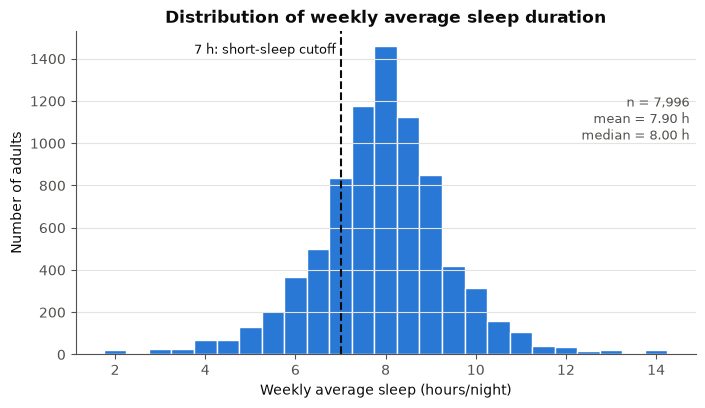

In [7]:
x = df["sleep_weekly"]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(x, bins=np.arange(1.75, 14.5, 0.5), color=COLORS["never"], edgecolor="white", linewidth=1)
ax.axvline(7, color=INK, linestyle="--", linewidth=1.5)
ax.text(6.9, ax.get_ylim()[1] * 0.93, "7 h: short-sleep cutoff", color=INK, fontsize=9, ha="right")
ax.set_title("Distribution of weekly average sleep duration")
ax.set_xlabel("Weekly average sleep (hours/night)")
ax.set_ylabel("Number of adults")
ax.text(0.99, 0.80, f"n = {len(x):,}\nmean = {x.mean():.2f} h\nmedian = {x.median():.2f} h",
        transform=ax.transAxes, ha="right", va="top", color=INK2, fontsize=9)
ax.grid(axis="x", visible=False)
save(fig, "fig01_sleep_weekly_hist.png"); plt.show()

<div dir="rtl">

**تفسیر:** بیشتر بزرگسالان بین ۷ تا ۹ ساعت می‌خوابند و قله‌ی توزیع حدود ۸ ساعت است. توزیع تقریباً متقارن است، ولی دنباله‌ی چپ (خواب‌های بسیار کوتاه) و چند مقدار در ۱۴ ساعت (کد سقف) دیده می‌شود. حدود یک‌پنجم افراد سمت چپ خط ۷ ساعت هستند.

</div>

<div dir="rtl">

### نمودار ۲ — خواب در سه گروه سیگار

</div>

C:\Users\SARIR\AppData\Local\Temp\ipykernel_19144\2111680804.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True,


Saved figures/fig02_sleep_by_smoking_box.png


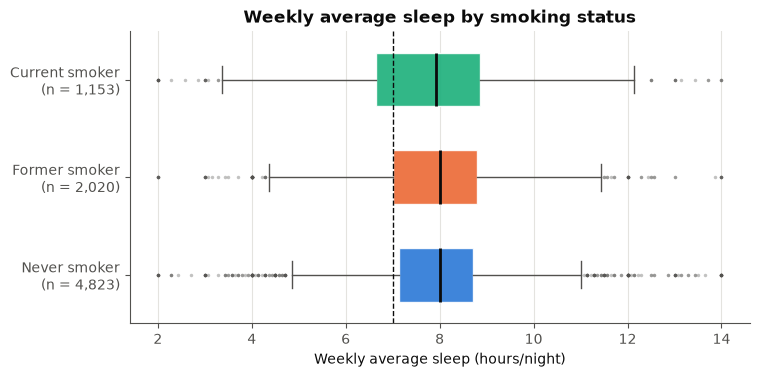

In [9]:
data = [df.loc[df["smoking_status"] == g, "sleep_weekly"] for g in GROUPS]
fig, ax = plt.subplots(figsize=(8, 3.8))
bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True,
                medianprops=dict(color=INK, linewidth=2),
                whiskerprops=dict(color=INK2), capprops=dict(color=INK2),
                flierprops=dict(marker="o", markersize=2.5, markerfacecolor=INK2,
                                markeredgecolor="none", alpha=0.35))
for patch, g in zip(bp["boxes"], GROUPS):
    patch.set_facecolor(COLORS[g]); patch.set_edgecolor("white"); patch.set_alpha(0.9)
ax.set_yticks(range(1, 4), [f"{LABELS[g]}\n(n = {len(d):,})" for g, d in zip(GROUPS, data)])
ax.axvline(7, color=INK, linestyle="--", linewidth=1)
ax.set_title("Weekly average sleep by smoking status")
ax.set_xlabel("Weekly average sleep (hours/night)")
ax.grid(axis="y", visible=False)
save(fig, "fig02_sleep_by_smoking_box.png"); plt.show()

<div dir="rtl">

**چطور بخوانیم:** خط سیاه داخل جعبه = میانه؛ لبه‌های جعبه = چارک اول و سوم (۵۰٪ وسط داده‌ها)؛ خطوط بیرونی = دامنه‌ی معمول؛ نقطه‌ها = مقادیر دورافتاده.

**تفسیر:** میانه‌ی هر سه گروه حدود ۸ ساعت است. تفاوت اصلی در **پراکندگی** است: جعبه‌ی سیگاری‌های فعلی پهن‌تر است و به سمت خواب کمتر کشیده شده (چارک اول حدود ۶.۶ ساعت در برابر ۷.۱ ساعت برای هرگز سیگاری‌ها).

</div>

<div dir="rtl">

### نمودار ۳ — درصد خواب کوتاه در هر گروه (وزن‌دار)

</div>

Saved figures/fig03_short_sleep_by_smoking.png


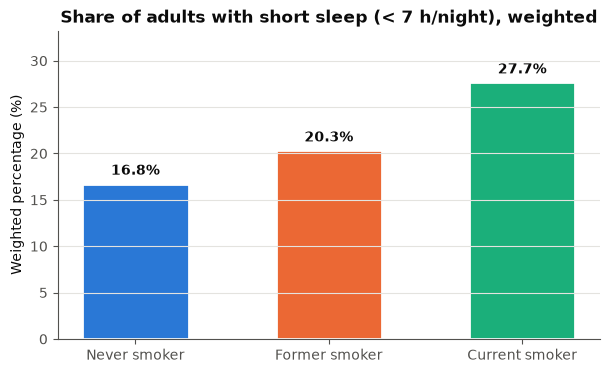

In [11]:
short_w = {g: nh.weighted_share(df.loc[df["smoking_status"] == g, "short_sleep"] == 1,
                                W[df["smoking_status"] == g]) * 100 for g in GROUPS}
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([LABELS[g] for g in GROUPS], [short_w[g] for g in GROUPS],
              color=[COLORS[g] for g in GROUPS], width=0.55, edgecolor="white", linewidth=2)
for b, g in zip(bars, GROUPS):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.6, f"{short_w[g]:.1f}%",
            ha="center", va="bottom", color=INK, fontsize=10, fontweight="bold")
ax.set_ylim(0, max(short_w.values()) * 1.2)
ax.set_title("Share of adults with short sleep (< 7 h/night), weighted")
ax.set_ylabel("Weighted percentage (%)")
ax.grid(axis="x", visible=False)
save(fig, "fig03_short_sleep_by_smoking.png"); plt.show()

<div dir="rtl">

**تفسیر:** سهم خواب کوتاه در سیگاری‌های فعلی (حدود ۲۸٪) به‌طور محسوسی بیشتر از هرگز سیگاری‌ها (حدود ۱۷٪) است و سیگاری‌های سابق در میانه قرار دارند. این همان الگوی فرضیه‌ی ماست، ولی هنوز **فقط توصیف** است.

</div>

<div dir="rtl">

### نمودار ۴ — سن در سه گروه سیگار

</div>

C:\Users\SARIR\AppData\Local\Temp\ipykernel_19144\501042722.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True,


Saved figures/fig04_age_by_smoking_box.png


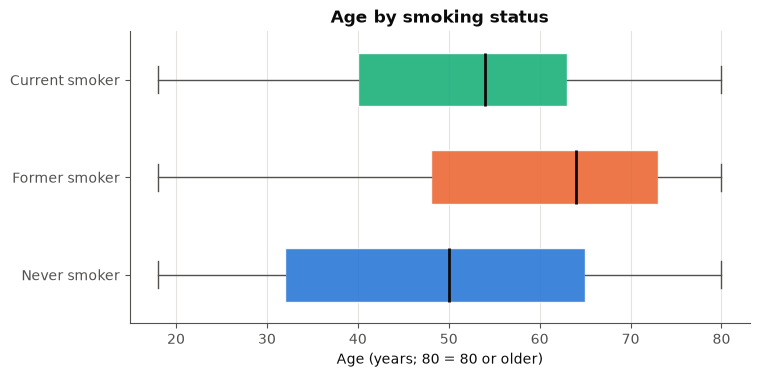

In [12]:
data = [df.loc[df["smoking_status"] == g, "RIDAGEYR"] for g in GROUPS]
fig, ax = plt.subplots(figsize=(8, 3.8))
bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True,
                medianprops=dict(color=INK, linewidth=2),
                whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
for patch, g in zip(bp["boxes"], GROUPS):
    patch.set_facecolor(COLORS[g]); patch.set_edgecolor("white"); patch.set_alpha(0.9)
ax.set_yticks(range(1, 4), [LABELS[g] for g in GROUPS])
ax.set_title("Age by smoking status")
ax.set_xlabel("Age (years; 80 = 80 or older)")
ax.grid(axis="y", visible=False)
save(fig, "fig04_age_by_smoking_box.png"); plt.show()

<div dir="rtl">

**تفسیر:** گروه‌ها از نظر سنی متفاوت‌اند: سیگاری‌های سابق به‌طور واضح مسن‌ترند (طبیعی است؛ ترک سیگار معمولاً در سنین بالاتر اتفاق می‌افتد). این یعنی سن می‌تواند در مقایسه‌ی خواب گروه‌ها **مخدوش‌کننده** باشد؛ دلیل اینکه در فاز چهارم سن را کنترل می‌کنیم.

</div>

<div dir="rtl">

### نمودار ۵ — خواب بر حسب گروه سنی و وضعیت سیگار

</div>

Saved figures/fig05_sleep_by_age_and_smoking.png


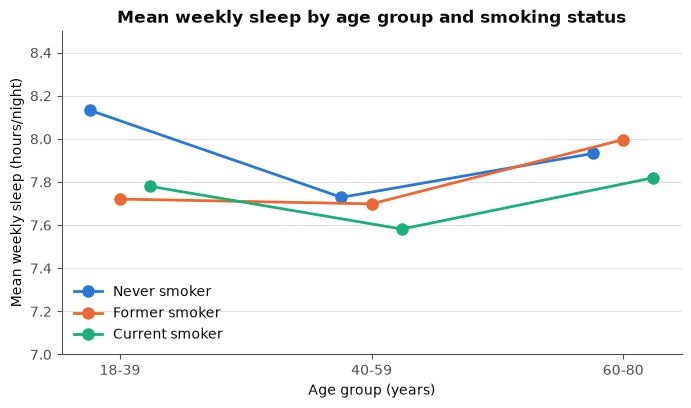

smoking_status,never,former,current
age_group,,,
18-39,8.13,7.72,7.78
40-59,7.73,7.70,7.58
60-80,7.93,8.00,7.82


In [13]:
df["age_group"] = pd.cut(df["RIDAGEYR"], [17, 39, 59, 80], labels=["18-39", "40-59", "60-80"])
tab = df.groupby(["age_group", "smoking_status"], observed=True)["sleep_weekly"].mean().unstack()[GROUPS]

fig, ax = plt.subplots(figsize=(8, 4.2))
xpos = np.arange(len(tab.index))
for i, g in enumerate(GROUPS):
    ax.plot(xpos + (i - 1) * 0.12, tab[g], marker="o", markersize=8, linewidth=2,
            color=COLORS[g], label=LABELS[g])
ax.set_xticks(xpos, tab.index)
ax.set_ylim(7.0, 8.5)
ax.set_title("Mean weekly sleep by age group and smoking status")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Mean weekly sleep (hours/night)")
ax.legend(frameon=False, loc="lower left")
ax.grid(axis="x", visible=False)
save(fig, "fig05_sleep_by_age_and_smoking.png"); plt.show()
tab

<div dir="rtl">

**تفسیر:**
- در **هر سه گروه سنی**، سیگاری‌های فعلی کمتر از افراد هرگز سیگاری می‌خوابند. یعنی تفاوت این دو گروه صرفاً به خاطر تفاوت سنی‌شان نیست.
- مقایسه با سیگاری‌های سابق یکدست نیست: در گروه ۱۸–۳۹ سال، سیگاری‌های سابق حتی کمی کمتر از سیگاری‌های فعلی می‌خوابند (این زیرگروه کوچک است و تفاوت‌ها چند دقیقه‌اند).
- گروه سنی ۴۰–۵۹ در همه‌ی گروه‌های سیگار کمترین خواب را دارد، و بیشترین سهم سیگاری‌های فعلی هم در همین گروه سنی است؛ پس بخشی از تفاوت کلی ممکن است به سن مربوط باشد.
- محور عمودی از صفر شروع نمی‌شود (۷ تا ۸.۵ ساعت) تا تفاوت‌ها دیده شوند؛ تفاوت‌ها در حد چند ده دقیقه‌اند، نه چند ساعت.

سنجش دقیق اثر سن کار فاز چهارم (رگرسیون با کنترل سن) است.

</div>

<div dir="rtl">

### نمودار ۶ — تعداد نخ در روز (سیگاری‌های فعلی)

</div>

Saved figures/fig06_cigs_per_day_hist.png


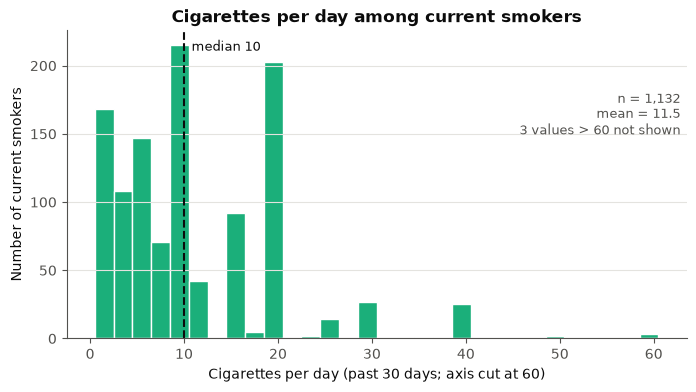

In [14]:
c = df["cigs_per_day"].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(c, bins=np.arange(0.5, 61.5, 2), color=COLORS["current"], edgecolor="white", linewidth=1)
ax.axvline(c.median(), color=INK, linestyle="--", linewidth=1.5)
ax.text(c.median() + 0.8, ax.get_ylim()[1] * 0.97, f"median {c.median():.0f}", color=INK, fontsize=9, va="top")
ax.set_title("Cigarettes per day among current smokers")
ax.set_xlabel("Cigarettes per day (past 30 days; axis cut at 60)")
ax.set_ylabel("Number of current smokers")
ax.text(0.99, 0.80, f"n = {len(c):,}\nmean = {c.mean():.1f}\n{(c > 60).sum()} values > 60 not shown",
        transform=ax.transAxes, ha="right", va="top", color=INK2, fontsize=9)
ax.grid(axis="x", visible=False)
save(fig, "fig06_cigs_per_day_hist.png"); plt.show()

<div dir="rtl">

**تفسیر:** توزیع به‌شدت **چوله به راست** است: بیشتر سیگاری‌ها روزانه کمتر از ۲۰ نخ (یک پاکت) می‌کشند، ولی چند نفر مصرف بسیار بالایی دارند. قله‌های کوچک روی ۱۰ و ۲۰ نخ احتمالاً به خاطر **گرد کردن پاسخ‌ها** است (مردم می‌گویند «نصف پاکت» یا «یک پاکت»). این یک نکته‌ی کیفیت اندازه‌گیری است.

</div>

<div dir="rtl">

## ۴. مقایسه‌ی توصیفی سه گروه (تسک ۹)

این جدول اصلی‌ترین خروجی توصیفی پروژه است. **بدون هیچ ادعای استنباطی.**

</div>

In [16]:
rows = []
for g in GROUPS:
    d = df[df["smoking_status"] == g]
    w = d["WTINT2YR"]
    s = d["sleep_weekly"]
    rows.append({
        "group": g, "n": len(d),
        "sleep_mean": s.mean(), "sleep_sd": s.std(), "sleep_median": s.median(),
        "sleep_q1": s.quantile(0.25), "sleep_q3": s.quantile(0.75),
        "short_sleep_pct": d["short_sleep"].mean() * 100,
        "sleep_mean_w": nh.weighted_mean(s, w),
        "short_sleep_pct_w": nh.weighted_share(d["short_sleep"] == 1, w) * 100,
        "age_mean": d["RIDAGEYR"].mean(),
        "male_pct": (d["RIAGENDR"] == 1).mean() * 100,
    })
group_compare = pd.DataFrame(rows).set_index("group")
group_compare.round(2).to_csv(TAB_DIR / "group_comparison.csv")
group_compare

,n,sleep_mean,sleep_sd,sleep_median,sleep_q1,sleep_q3,short_sleep_pct,sleep_mean_w,short_sleep_pct_w,age_mean,male_pct
group,,,,,,,,,,,
never,4823,7.95,1.43,8.00,7.14,8.71,17.91,7.95,16.75,48.91,39.60
former,2020,7.88,1.53,8.00,7.00,8.79,20.10,7.87,20.34,59.87,51.93
current,1153,7.72,1.77,7.93,6.64,8.86,28.19,7.72,27.68,51.53,53.17


In [17]:
diff_min = (group_compare.loc["never", "sleep_mean"] - group_compare.loc["current", "sleep_mean"]) * 60
diff_pp = group_compare.loc["current", "short_sleep_pct"] - group_compare.loc["never", "short_sleep_pct"]
print(f"Mean sleep: current smokers sleep about {diff_min:.0f} minutes less than never smokers")
print(f"Short sleep: {diff_pp:.1f} percentage points higher in current smokers than never smokers")

Mean sleep: current smokers sleep about 14 minutes less than never smokers
Short sleep: 10.3 percentage points higher in current smokers than never smokers


<div dir="rtl">

**جمع‌بندی توصیفی:**
- **میانگین** خواب سیگاری‌های فعلی حدود ۱۴ دقیقه کمتر از هرگز سیگاری‌هاست؛ تفاوتی کوچک.
- **سهم خواب کوتاه** در سیگاری‌های فعلی حدود ۱۰ واحد درصد بیشتر است؛ تفاوتی محسوس‌تر.
- **انحراف معیار** خواب در سیگاری‌های فعلی بیشتر است: الگوی خوابشان ناهمگن‌تر است.
- گروه‌ها از نظر **سن و جنسیت** متفاوت‌اند؛ پس این تفاوت‌ها هنوز «خام»اند و نمی‌توان آن‌ها را به سیگار نسبت داد.

**جمله‌ای که نباید گفت:** «سیگار باعث کم‌خوابی می‌شود.» **جمله‌ی درست:** «در این نمونه، سیگاری‌های فعلی به‌طور توصیفی سهم بیشتری از خواب کوتاه گزارش کرده‌اند.»

</div>

<div dir="rtl">

## ۵. خلاصه‌ی ساده در برابر وزن‌دار (تسک الف.۳)

برای چند کمیت کلیدی، نسخه‌ی بدون وزن (توصیف **نمونه**) و وزن‌دار (برآورد **جمعیت آمریکا**) را کنار هم می‌گذاریم.

</div>

In [19]:
s = df["sleep_weekly"]
compare = pd.DataFrame({
    "unweighted": [
        s.mean(), s.median(), df["short_sleep"].mean() * 100,
        (df["smoking_status"] == "current").mean() * 100, df["RIDAGEYR"].mean(),
        (df["RIDAGEYR"] >= 60).mean() * 100,
    ],
    "weighted": [
        nh.weighted_mean(s, W), nh.weighted_quantile(s, W, 0.5),
        nh.weighted_share(df["short_sleep"] == 1, W) * 100,
        nh.weighted_share(df["smoking_status"] == "current", W) * 100,
        nh.weighted_mean(df["RIDAGEYR"], W),
        nh.weighted_share(df["RIDAGEYR"] >= 60, W) * 100,
    ],
}, index=["Mean weekly sleep (h)", "Median weekly sleep (h)", "Short sleep (%)",
          "Current smokers (%)", "Mean age (years)", "Aged 60+ (%)"])
compare["difference"] = compare["weighted"] - compare["unweighted"]
compare.round(2).to_csv(TAB_DIR / "weighted_vs_unweighted.csv")
compare

,unweighted,weighted,difference
Mean weekly sleep (h),7.90,7.90,-0.00
Median weekly sleep (h),8.00,8.00,0.00
Short sleep (%),19.95,19.11,-0.83
Current smokers (%),14.42,14.08,-0.34
Mean age (years),52.06,47.72,-4.33
Aged 60+ (%),42.83,30.00,-12.83


<div dir="rtl">

**تفسیر:**
- **سن بیشترین تفاوت را دارد:** میانگین سن نمونه حدود ۵۲ سال است ولی برآورد وزن‌دار حدود ۴۸ سال. دلیلش طرح نمونه‌گیری است: همه‌ی افراد ۶۰+ ساله‌ی هر خانوار انتخاب شده‌اند، پس سالمندها در نمونه **بیش از سهم واقعی‌شان** حضور دارند. وزن‌ها این را اصلاح می‌کنند و سهم ۶۰+ ساله‌ها را پایین می‌آورند.
- **خواب تقریباً تغییر نمی‌کند:** چون خواب در گروه‌های سنی خیلی متفاوت نیست، اصلاح سهم سنی، میانگین خواب را چندان تغییر نمی‌دهد.
- **سهم خواب کوتاه کمی کاهش می‌یابد** و سهم سیگاری‌های فعلی تقریباً ثابت می‌ماند.

**درس این بخش:** اینکه وزن‌دهی یک نتیجه را زیاد تغییر دهد یا نه، به این بستگی دارد که آن متغیر با ویژگی‌هایی که نمونه‌گیری بر اساسشان نابرابر بوده (مثل سن) چقدر مرتبط است. برای ادعا درباره‌ی **جمعیت آمریکا** باید از نسخه‌ی وزن‌دار استفاده کرد.

</div>

<div dir="rtl">

## جمع‌بندی نوت‌بوک ۰۳

| خروجی | فایل |
|---|---|
| جدول‌های فراوانی | `reports/phase1/freq_*.csv` |
| مرکز و پراکندگی | `reports/phase1/center_spread.csv` |
| مقایسه‌ی گروه‌ها | `reports/phase1/group_comparison.csv` |
| ساده در برابر وزن‌دار | `reports/phase1/weighted_vs_unweighted.csv` |
| ۶ نمودار | `figures/fig01` تا `fig06` |

**یافته‌ی اصلی توصیفی:** سیگاری‌های فعلی سهم بیشتری از خواب کوتاه دارند (حدود ۲۸٪ در برابر ۱۷٪)، ولی میانگین خوابشان فقط کمی کمتر است. گروه‌ها از نظر سن متفاوت‌اند، پس سن باید در فازهای بعد کنترل شود.

</div>